In [33]:
from microtorch.model_maker import ModelMaker
from microtool.microtorch import MicrotorchTissueModel
from microtool.tissue_model import MultiTissueModel, RelaxationTissueModel
from microtool.utils.unit_registry import unit

microtorch_model = ModelMaker("SphereBallAstrosticks")
sphere, ball, astrosticks = microtorch_model.compartments

# Keep the requested compartment settings.
sphere.fixed_D = 2
astrosticks.fixed_D_par = 8.0
astrosticks.parameter_ranges = [[8.0, 8.0]]

# Wrap each compartment individually, not the combined ModelMaker model.
sphere_model = MicrotorchTissueModel(
    sphere,
    parameters={"radius": 6.0},
)
ball_model = MicrotorchTissueModel(
    ball,
    parameters={"D": 2.0},
)
astrosticks_model = MicrotorchTissueModel(
    astrosticks,
    parameters={"D_par": 8.0},
)

# Hold these diffusivities fixed during fitting.
for compartment in (ball_model, astrosticks_model):
    for name in ("D", "D_par"):
        if name in compartment:
            compartment[name].optimize = False
            compartment[name].fit_flag = False

#sphere_model["radius"].value_list = list(range(5, 16))

sphere_relax = RelaxationTissueModel(sphere_model, t2=100e-3 * unit("s"))
ball_relax = RelaxationTissueModel(ball_model, t2=250e-3 * unit("s"))
astrosticks_relax = RelaxationTissueModel(
    astrosticks_model,
    t2=250e-3 * unit("s"),
)


#These T2 values are used for prediction but not estimated or optimized.
for compartment in (sphere_relax, ball_relax, astrosticks_relax):
    compartment["T2"].optimize = False
    compartment["T2"].fit_flag = False
    compartment["T2"].scale = 1


vfs = [0.6, 0.35]
vfs.append(1.0 - sum(vfs))

model = MultiTissueModel(
    [sphere_relax, ball_relax, astrosticks_relax],
    volume_fractions=vfs,
)

model["vf_0"].fit_flag = True

model["vf_2"].optimize = False
model["vf_2"].fit_flag = False

model["S0"].optimze = False
model["S0"].fit_flag = False
print(model)

No YAML configuration found for SphereBallAstrosticks model.
Falling back to parsing model name for compartments: ['Sphere', 'Ball', 'Astrosticks'].
Parameter ranges will be the default compartment values.
-----------
########### Making model:  SphereBallAstrosticks
########### Compartments: ['Sphere', 'Ball', 'Astrosticks']
########### Parameter names: [['radius'], ['D'], ['D_par']]
########### Parameter ranges: [[[0.001, 15]], [[0.001, 3]], [[0.5, 3.0]]]
-----------
Tissue model with 10 scalar parameters:
Tissue-parameter        Value    Scale  Optimize    Fit    Fit Bounds
--------------------  -------  -------  ----------  -----  -------------
model_0_model_radius     6           1  True        True   (0.001, 15.0)
model_0_T2               0.1         1  False       False  (0.0001, 1.0)
model_1_model_D          2           1  False       False  (0.001, 3.0)
model_1_T2               0.25        1  False       False  (0.0001, 1.0)
model_2_model_D_par      8           1  False       F

In [34]:
import numpy as np
from microtool.acquisition_scheme import DiffusionAcquisitionScheme
from microtool.gradient_sampling import sample_uniform_half_sphere

n_directions = 6
n_shells = 5
block_size = n_directions + 1  # b0 + n_directions

# shell_bvals = [1500, 1000, 2200, 2500, 2500]
# shell_deltas = [0.0258, 0.0205,0.0205,0.0334, 0.0334]
# shell_Deltas = [0.0434, 0.0431,0.0431, 0.0455, 0.0455]
# initial_te = 0.09


shell_bvals = [2999, 2000, 1500, 500, 90]
shell_deltas = [0.0247, 0.0132, 0.0247, 0.0122, 0.0122]
shell_Deltas = [0.0438, 0.0323, 0.0434, 0.0313, 0.0238]
initial_te = [0.090, 0.067, 0.090, 0.065, 0.050]
# Build the measurements in shell blocks: b0, then six directions.
b_vals_list = []
pulse_durations_list = []
pulse_intervals_list = []
echo_times_list = []

for i in range(n_shells):
    b_vals_list.append(0.0)
    b_vals_list.extend([shell_bvals[i]] * n_directions)

    pulse_durations_list.extend([shell_deltas[i]] * block_size)
    pulse_intervals_list.extend([shell_Deltas[i]] * block_size)
    echo_times_list.extend([initial_te[i]] * block_size)

b_vals = np.array(b_vals_list)
pulse_durations = np.array(pulse_durations_list)
pulse_intervals = np.array(pulse_intervals_list)
echo_times = np.array(echo_times_list)
directions = sample_uniform_half_sphere(len(b_vals))

initial_scheme = DiffusionAcquisitionScheme.from_bvals(
    b_values=b_vals,
    b_vectors=directions,
    pulse_durations=pulse_durations,
    pulse_intervals=pulse_intervals,
    echo_times=echo_times,
)

# One optimized TE, delta, and Delta per shell, shared across that shell's
# b0 and diffusion-weighted measurements.
for name in (
    "EchoTime",
    "DiffusionPulseDuration",
    "DiffusionPulseInterval",
):
    initial_scheme[name].set_repetition_period(block_size)

# Keep each b0 gradient magnitude fixed at zero.
# All diffusion-weighted gradient magnitudes remain independently optimizable.
b0_mask = np.isclose(b_vals, 0.0)
magnitude = initial_scheme["DiffusionPulseMagnitude"]
magnitude.set_fixed_mask(b0_mask)

magnitude.set_fixed_mask(b0_mask)
magnitude.set_repetition_period(n_directions)

# Check the masks and b0 values.
print("Timing free indices:",
      np.flatnonzero(initial_scheme["EchoTime"].optimize_mask))
print("Gradient-magnitude free indices:",
      np.flatnonzero(magnitude.optimize_mask))
print("b0 gradient magnitudes:", magnitude.values[b0_mask])

assert np.all(magnitude.values[b0_mask] == 0.0)
assert not np.any(magnitude.optimize_mask[b0_mask])

print(magnitude.optimize_mask)
print(initial_scheme)


Timing free indices: [ 0  7 14 21 28]
Gradient-magnitude free indices: [ 1  8 15 22 29]
b0 gradient magnitudes: [-0. -0. -0. -0. -0.]
[False  True False False False False False False  True False False False
 False False False  True False False False False False False  True False
 False False False False False  True False False False False False]
Acquisition scheme with 35 measurements and 6 scalar parameters. 
total number of optimized parameters is 20:
  DiffusionPulseMagnitude [mT/mm] in (0.0, 660)    DiffusionGradientAnglePhi [rad] (fixed)    DiffusionGradientAngleTheta [rad] (fixed)    DiffusionPulseDuration [s] in (0.01, 0.1)    DiffusionPulseInterval [s] in (0.01, 0.1)    EchoTime [s] in (0.01, 0.1)
-----------------------------------------------  -----------------------------------------  -------------------------------------------  -------------------------------------------  -------------------------------------------  -----------------------------
                            

In [35]:
from copy import deepcopy
import numpy as np

scheme = deepcopy(initial_scheme)
x0 = scheme.scaled_free_parameter_vector.copy()

for name, constraint in scheme.constraints.items():
    scheme.set_scaled_free_parameter_vector(x0)
    values = np.atleast_1d(constraint.fun(x0))
    print(
        name,
        "values:", values.shape,
        "lower bounds:", np.shape(constraint.lb),
        "upper bounds:", np.shape(constraint.ub),
    )

scheme.set_scaled_free_parameter_vector(x0)

PulseIntervalLargerThanPulseDuration values: (35,) lower bounds: () upper bounds: ()
PulseMagnitudeSmallerThanMaxMagnitude values: (35,) lower bounds: () upper bounds: ()
EchoTimeLargerThanMinEchoTime values: (35,) lower bounds: () upper bounds: ()
BValueWithinBounds values: (30,) lower bounds: () upper bounds: ()


In [36]:
signal = model(initial_scheme)
print(signal)

[0.52301233 0.21309614 0.21309614 0.21309614 0.21309614 0.21309614
 0.21309614 0.61298826 0.25870399 0.25870399 0.25870399 0.25870399
 0.25870399 0.25870399 0.52301233 0.24512939 0.24512939 0.24512939
 0.24512939 0.24512939 0.24512939 0.6216481  0.41117967 0.41117967
 0.41117967 0.41117967 0.41117967 0.41117967 0.6914107  0.63083676
 0.63083676 0.63083676 0.63083676 0.63083676 0.63083676]


In [37]:
jacobian = model.scaled_jacobian(initial_scheme)
print(jacobian)
print(jacobian.shape)

[[ 0.         -0.29110667  0.        ]
 [-0.02075985  0.21739927 -0.12449808]
 [-0.02075985  0.21739927 -0.12449808]
 [-0.02075985  0.21739927 -0.12449808]
 [-0.02075985  0.21739927 -0.12449808]
 [-0.02075985  0.21739927 -0.12449808]
 [-0.02075985  0.21739927 -0.12449808]
 [ 0.         -0.2531992   0.        ]
 [-0.02965561  0.23940793 -0.1554607 ]
 [-0.02965561  0.23940793 -0.1554607 ]
 [-0.02965561  0.23940793 -0.1554607 ]
 [-0.02965561  0.23940793 -0.1554607 ]
 [-0.02965561  0.23940793 -0.1554607 ]
 [-0.02965561  0.23940793 -0.1554607 ]
 [ 0.         -0.29110667  0.        ]
 [-0.01140742  0.19492524 -0.14375229]
 [-0.01140742  0.19492524 -0.14375229]
 [-0.01140742  0.19492524 -0.14375229]
 [-0.01140742  0.19492524 -0.14375229]
 [-0.01140742  0.19492524 -0.14375229]
 [-0.01140742  0.19492524 -0.14375229]
 [ 0.         -0.24900581  0.        ]
 [-0.00942538  0.15143068 -0.05641112]
 [-0.00942538  0.15143068 -0.05641112]
 [-0.00942538  0.15143068 -0.05641112]
 [-0.00942538  0.15143068

In [38]:
from microtool.optimize import optimize_scheme

optimal_scheme_initial, _ = optimize_scheme(initial_scheme, model, noise_variance=0.02, method="trust-constr", solver_options = {
    "verbose": 2,
    "maxiter": 1000,
    #"finite_diff_rel_step": 1e-8,  # Prevents large jumps during gradient estimation
    #"initial_tr_radius": 0.05        # Prevents trust radius from jumping to 35.0
})

/smb/user/jgroot34/DS-Data/Radiotherapie/Research/User/jgroot34/D_Projects/MICROtool/MICROtool_Github/microtool/microtool/tissue_model.py:671: UserWarning: If T2 relaxation is not used for fitting, echo time should be fixed.
  warnings.warn("If T2 relaxation is not used for fitting, echo time should be fixed.")


| niter |f evals|CG iter|  obj func   |tr radius |   opt    |  c viol  |
|-------|-------|-------|-------------|----------|----------|----------|
|   1   |  21   |   0   | +2.1549e+01 | 1.00e+00 | 4.18e+00 | 0.00e+00 |


/nfs/rtfs03/storage/home/jgroot34/miniforge3/envs/MICROtool/lib/python3.11/site-packages/scipy/optimize/_differentiable_functions.py:737: UserWarning: delta_grad == 0.0. Check if the approximated function is linear. If the function is linear better results can be obtained by defining the Hessian as zero instead of using quasi-Newton approximations.
  self.H.update(delta_x, delta_g)


|   2   |  42   |   1   | +1.6845e+01 | 2.00e+00 | 1.91e+01 | 1.83e-02 |
|   3   |  63   |  19   | +1.7033e+01 | 1.31e+01 | 3.86e+01 | 0.00e+00 |
|   4   |  84   |  37   | +1.5210e+01 | 1.31e+01 | 8.34e+01 | 0.00e+00 |
|   5   |  105  |  57   | +9.8302e+00 | 1.81e+01 | 5.55e+00 | 0.00e+00 |
|   6   |  126  |  77   | +8.3701e+00 | 1.81e+01 | 5.83e+00 | 0.00e+00 |
|   7   |  147  |  87   | +8.3759e+00 | 1.81e+01 | 2.43e+00 | 0.00e+00 |
|   8   |  168  |  107  | +8.1318e+00 | 1.81e+01 | 5.23e+00 | 0.00e+00 |
|   9   |  189  |  127  | +7.7545e+00 | 1.81e+01 | 3.52e+00 | 0.00e+00 |
|  10   |  210  |  147  | +7.3716e+00 | 1.81e+01 | 7.07e-01 | 0.00e+00 |
|  11   |  252  |  167  | +7.4162e+00 | 1.81e+01 | 2.12e+00 | 0.00e+00 |
|  12   |  294  |  187  | +7.4162e+00 | 1.81e+00 | 2.12e+00 | 0.00e+00 |
|  13   |  315  |  207  | +7.3963e+00 | 1.81e+00 | 3.28e+00 | 0.00e+00 |
|  14   |  336  |  224  | +7.3954e+00 | 1.81e+00 | 4.05e+00 | 0.00e+00 |
|  15   |  378  |  242  | +7.3954e+00 | 9.06e-01 | 

/nfs/rtfs03/storage/home/jgroot34/miniforge3/envs/MICROtool/lib/python3.11/site-packages/scipy/optimize/_differentiable_functions.py:385: UserWarning: delta_grad == 0.0. Check if the approximated function is linear. If the function is linear better results can be obtained by defining the Hessian as zero instead of using quasi-Newton approximations.
  self.H.update(self.x - self.x_prev, self.g - self.g_prev)


|  91   | 2562  | 1394  | +6.9242e+00 | 3.05e-07 | 7.51e+00 | 0.00e+00 |
|  92   | 2604  | 1395  | +6.9242e+00 | 1.53e-07 | 7.51e+00 | 0.00e+00 |
|  93   | 2646  | 1396  | +6.9242e+00 | 7.63e-08 | 7.51e+00 | 0.00e+00 |
|  94   | 2688  | 1397  | +6.9242e+00 | 3.19e-08 | 7.51e+00 | 0.00e+00 |
|  95   | 2730  | 1398  | +6.9242e+00 | 7.33e-09 | 7.51e+00 | 0.00e+00 |
|  96   | 2751  | 1398  | +6.9242e+00 | 1.00e+00 | 7.56e+00 | 0.00e+00 |
|  97   | 2772  | 1418  | +6.8829e+00 | 1.00e+00 | 6.76e+00 | 0.00e+00 |
|  98   | 2814  | 1436  | +6.8829e+00 | 1.00e-01 | 6.76e+00 | 0.00e+00 |
|  99   | 2835  | 1453  | +6.8769e+00 | 1.00e-01 | 1.00e+00 | 0.00e+00 |
|  100  | 2877  | 1471  | +6.8769e+00 | 4.07e-02 | 1.00e+00 | 0.00e+00 |
|  101  | 2898  | 1491  | +6.8646e+00 | 8.14e-02 | 2.90e+00 | 0.00e+00 |
|  102  | 2940  | 1504  | +6.8646e+00 | 4.07e-02 | 2.90e+00 | 0.00e+00 |
|  103  | 2982  | 1515  | +6.8646e+00 | 2.03e-02 | 2.90e+00 | 0.00e+00 |
|  104  | 3024  | 1528  | +6.8646e+00 | 1.02e-02 | 

In [39]:
# import microtool.optimize.methods as methods
# from microtool.optimize import optimize_scheme

# import numpy as np
# from microtool.optimize.loss_functions import compute_loss, gauss_loss



# method = methods.SOMA()
# optimal_scheme, _ = optimize_scheme(
#     initial_scheme, model, noise_variance=0.02, method=method
# )

In [40]:
import numpy as np
import pandas as pd


def get_unique_shells(scheme, scheme_name="Scheme"):
    df = pd.DataFrame(
        {
            "Scheme": scheme_name,
            "b_value": np.round(scheme.b_values, 1),
            "TE_ms": np.round(scheme.echo_times * 1e3, 2),
            "delta_ms": np.round(scheme.pulse_durations * 1e3, 2),
            "Delta_ms": np.round(scheme.pulse_intervals * 1e3, 2),
        }
    )

    # Filter out b = 0
    df_nonzero = df[df["b_value"] > 0]

    # Group by unique parameters and count directions
    shells = (
        df_nonzero.groupby(
            ["Scheme", "b_value", "TE_ms", "delta_ms", "Delta_ms"], as_index=False
        )
        .size()
        .rename(columns={"size": "N_directions"})
    )
    return shells


# Combine initial and optimal shells
shells_initial = get_unique_shells(initial_scheme, scheme_name="Initial")
shells_optimal = get_unique_shells(optimal_scheme_initial, scheme_name="Optimal")

combined_shells = pd.concat([shells_initial, shells_optimal], ignore_index=True)

print(combined_shells.to_string(index=False))

 Scheme  b_value  TE_ms  delta_ms  Delta_ms  N_directions
Initial     90.0  50.00     12.20     23.80             6
Initial    500.0  65.00     12.20     31.30             6
Initial   1500.0  90.00     24.70     43.40             6
Initial   2000.0  67.00     13.20     32.30             6
Initial   2999.0  90.00     24.70     43.80             6
Optimal    158.0  56.06     15.11     25.07             6
Optimal   1094.4  77.39     12.05     42.37             6
Optimal   1211.7  91.22     27.57     48.03             6
Optimal   1252.8  92.93     29.70     47.87             6
Optimal   2950.6  37.92     11.51     20.71             6


In [41]:
print(model)

Tissue model with 10 scalar parameters:
Tissue-parameter        Value    Scale  Optimize    Fit    Fit Bounds
--------------------  -------  -------  ----------  -----  -------------
model_0_model_radius     6           1  True        True   (0.001, 15.0)
model_0_T2               0.1         1  False       False  (0.0001, 1.0)
model_1_model_D          2           1  False       False  (0.001, 3.0)
model_1_T2               0.25        1  False       False  (0.0001, 1.0)
model_2_model_D_par      8           1  False       False  (8.0, 8.0)
model_2_T2               0.25        1  False       False  (0.0001, 1.0)
vf_0                     0.6         1  True        True   (0.0, 1.0)
vf_1                     0.35        1  True        True   (0.0, 1.0)
vf_2                     0.05        1  False       False  (0.0, 1.0)
S0                       1           1  False       False  (0.0, 2.0)


In [42]:
from microtool.monte_carlo.simulation import MonteCarloSimulation
from scipy import stats

print(model)
# loc is mean and scale is standard deviation
noise_distribution = stats.norm(loc=0, scale=0.02)

# Perform a Monte Carlo simulation using the initial scheme.
simulation = MonteCarloSimulation(
    initial_scheme,
    model,
    noise_distribution,
    n_sim=100,
    #fit_options={"diff_step": 1e-4},
)
simulation.run()
initial = simulation.result

# Repeat the simulation using the optimized scheme.
simulation.set_scheme(optimal_scheme_initial)
simulation.run()
optimal = simulation.result

Tissue model with 10 scalar parameters:
Tissue-parameter        Value    Scale  Optimize    Fit    Fit Bounds
--------------------  -------  -------  ----------  -----  -------------
model_0_model_radius     6           1  True        True   (0.001, 15.0)
model_0_T2               0.1         1  False       False  (0.0001, 1.0)
model_1_model_D          2           1  False       False  (0.001, 3.0)
model_1_T2               0.25        1  False       False  (0.0001, 1.0)
model_2_model_D_par      8           1  False       False  (8.0, 8.0)
model_2_T2               0.25        1  False       False  (0.0001, 1.0)
vf_0                     0.6         1  True        True   (0.0, 1.0)
vf_1                     0.35        1  True        True   (0.0, 1.0)
vf_2                     0.05        1  False       False  (0.0, 1.0)
S0                       1           1  False       False  (0.0, 2.0)


Starting Monte Carlo with 100 simulations:   0%|          | 0/100 [00:00<?, ?it/s]

/nfs/rtfs03/storage/home/jgroot34/miniforge3/envs/MICROtool/lib/python3.11/site-packages/scipy/optimize/_differentiable_functions.py:385: UserWarning: delta_grad == 0.0. Check if the approximated function is linear. If the function is linear better results can be obtained by defining the Hessian as zero instead of using quasi-Newton approximations.
  self.H.update(self.x - self.x_prev, self.g - self.g_prev)
Starting Monte Carlo with 100 simulations:   1%|          | 1/100 [00:00<01:32,  1.07it/s]/nfs/rtfs03/storage/home/jgroot34/miniforge3/envs/MICROtool/lib/python3.11/site-packages/scipy/optimize/_differentiable_functions.py:385: UserWarning: delta_grad == 0.0. Check if the approximated function is linear. If the function is linear better results can be obtained by defining the Hessian as zero instead of using quasi-Newton approximations.
  self.H.update(self.x - self.x_prev, self.g - self.g_prev)
Starting Monte Carlo with 100 simulations:   2%|▏         | 2/100 [00:01<01:35,  1.02it/

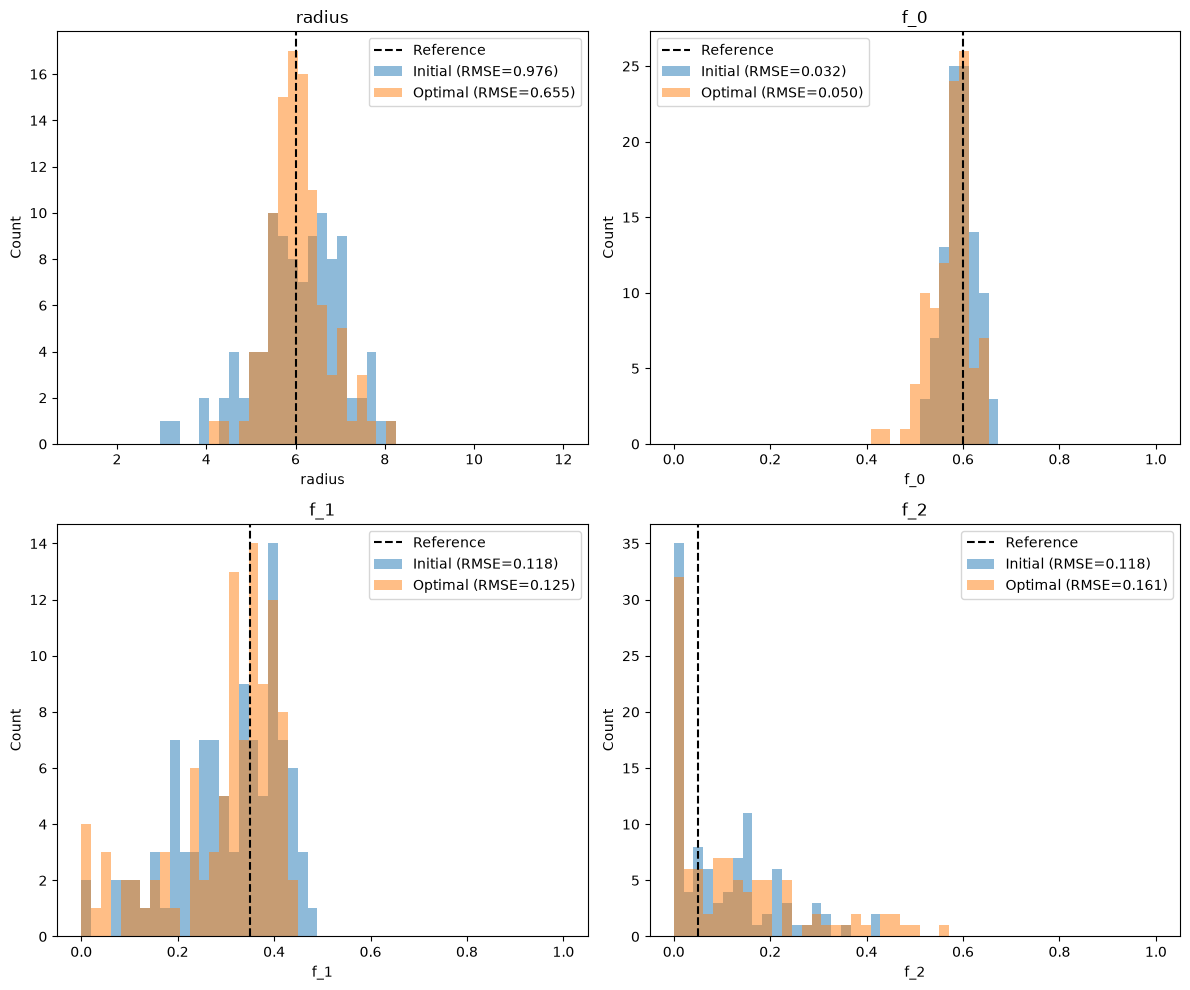

In [43]:
import numpy as np
from matplotlib import pyplot as plt

initial_result = initial
optimal_result = optimal

# 1. Compute derived fraction f_2 = 1 - vf_0 - vf_1 from simulation DataFrames
initial_f2 = 1.0 - initial_result["vf_0"] - initial_result["vf_1"]
optimal_f2 = 1.0 - optimal_result["vf_0"] - optimal_result["vf_1"]

# 2. Extract ground-truth reference values from model
radius_key = next((k for k in ["model_0_model_radius", "model_radius", "radius"] if k in model), None)
vf0_key = next((k for k in ["vf_0", "model_vf_0", "f_0", "model_f_0"] if k in model), None)
vf1_key = next((k for k in ["vf_1", "model_vf_1", "f_1", "model_f_1"] if k in model), None)

radius_ref = model[radius_key].value if radius_key else 0.0
f0_ref = model[vf0_key].value if vf0_key else 0.0
f1_ref = model[vf1_key].value if vf1_key else 0.0
f2_ref = 1.0 - f0_ref - f1_ref

# Column names matching the DataFrame output
radius_col = "model_0_model_radius"

plots_data = [
    (
        "radius",
        radius_ref,
        initial_result[radius_col],
        optimal_result[radius_col],
        np.linspace(0.2 * radius_ref, 2 * radius_ref, 50),
    ),
    (
        "f_0",
        f0_ref,
        initial_result["vf_0"],
        optimal_result["vf_0"],
        np.linspace(0, 1, 50),
    ),
    (
        "f_1",
        f1_ref,
        initial_result["vf_1"],
        optimal_result["vf_1"],
        np.linspace(0, 1, 50),
    ),
    (
        "f_2",
        f2_ref,
        initial_f2,
        optimal_f2,
        np.linspace(0, 1, 50),
    ),
]

# 3. Create 2x2 subplot grid
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.ravel()

for ax, (name, ref, init_vals, opt_vals, bins) in zip(axes, plots_data):
    init_rmse = np.sqrt(np.mean((init_vals - ref) ** 2))
    opt_rmse = np.sqrt(np.mean((opt_vals - ref) ** 2))

    ax.axvline(ref, color="black", linestyle="--", label="Reference")
    ax.hist(
        init_vals,
        bins=bins,
        alpha=0.5,
        label=f"Initial (RMSE={init_rmse:.3f})",
    )
    ax.hist(
        opt_vals,
        bins=bins,
        alpha=0.5,
        label=f"Optimal (RMSE={opt_rmse:.3f})",
    )

    ax.set_title(name)
    ax.set_xlabel(name)
    ax.set_ylabel("Count")
    ax.legend()

plt.tight_layout()
plt.show()